# 04 - Transfer learning: ResNet-18

**Owner:** Allison Landis - CSC 7333 Group 6

ResNet-18 (He et al., 2016) is pretrained on ImageNet (1.2M images). Initial convolutional layers of this model identify edges and patterns, both of which are also useful for facial expressions. This model's 1000-class output layer is replaced with a 6-class head. The model is then fine-tuned using the FERPlus dataset.

**Transfer learning in two stages**

1. *Head only*: Only the new 6-class head is trained as the rest of the model is kept fixed. If we were to train a randomly initialized head together with the backbone, then large and erratic gradients would be passed back to the pretrained model.
2. *Fine-tuning*: The whole model, or only its final stages, is unfrozen and trained. However, the pretrained layers are trained at a 10× lower learning rate than the head.

The 224×224 grayscale images are replicated across 3 channels and then normalized using ImageNet's mean and std, as this is what the pretrained filters expect.

**Run on Colab with a GPU** (T4). On a T4 the whole notebook takes about 66 minutes, including the tuning runs. Prior to execution, the `.npy` files should be uploaded to `MyDrive/ferplus/data`. Model weights and metrics are saved to `MyDrive/ferplus/`.

In [ ]:
import copy
import json
import shutil
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_recall_fscore_support
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision import models
from torchvision.transforms import v2

IMAGE_SIZE = 224

try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    # Place the 9 .npy files in MyDrive/ferplus/data. Model weights and metrics are saved to MyDrive/ferplus.
    try:
        drive.mount("/content/drive")
    except Exception as err:
        print("Could not mount Google Drive, so copy the .npy files to /content/data by hand:", err)
    DRIVE = Path("/content/drive/MyDrive/ferplus")
    DATA_DIR = Path("/content/data")
    DATA_DIR.mkdir(exist_ok=True)
    # As it is slow to retrieve large arrays from Drive, required files for this notebook are copied once. The
    # 48x48 data is always required as it is used to locate test images that are also in Train.
    for file in (DRIVE / "data").glob("*.npy"):
        needed = "labels" in file.name or "_48_" in file.name or f"_{IMAGE_SIZE}_" in file.name
        if needed and not (DATA_DIR / file.name).exists():
            shutil.copy(file, DATA_DIR)
    RESULTS_DIR, MODELS_DIR = DRIVE / "results", DRIVE / "models"
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    DATA_DIR, RESULTS_DIR, MODELS_DIR = ROOT / "data", ROOT / "results", ROOT / "models"

FIG = RESULTS_DIR / "figures"
for folder in (FIG, RESULTS_DIR / "metrics", MODELS_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print("data files:", sorted(p.name for p in DATA_DIR.glob("*.npy")))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
data: ['FER2013Test_224_images.npy', 'FER2013Test_48_images.npy', 'FER2013Test_labels.npy', 'FER2013Train_224_images.npy', 'FER2013Train_48_images.npy', 'FER2013Train_labels.npy', 'FER2013Valid_224_images.npy', 'FER2013Valid_48_images.npy', 'FER2013Valid_labels.npy']


In [2]:
SEED = 42
CLASSES = ["Neutral", "Happiness", "Surprise", "Sadness", "Anger", "Fear"]
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
MODEL_NAME = "resnet18"
# Prefix for parameter names in the new classifier section.
HEAD = "fc"


def load_split(split, size=48):
    # Images and classes for one split. Excludes Disgust and Contempt. As the 224x224 training data exceeds 1 GB,
    # memory mapping is used. Only the selected images are then copied.
    names = np.load(DATA_DIR / f"FER2013{split}_labels.npy")
    images = np.load(DATA_DIR / f"FER2013{split}_{size}_images.npy", mmap_mode="r")
    keep = np.isin(names, CLASSES)
    labels = np.array([CLASSES.index(name) for name in names[keep]])
    return np.ascontiguousarray(images[keep]), labels


def compute_metrics(y_true, y_pred):
    # Accuracy, macro and class level statistics and a confusion matrix. Output is in the format that notebook 06
    # expects.
    labels = range(len(CLASSES))
    precision, recall, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1.mean(),
        "macro_precision": precision.mean(),
        "macro_recall": recall.mean(),
        "per_class": {name: {"precision": precision[i], "recall": recall[i], "f1": f1[i], "support": int(support[i])}
                      for i, name in enumerate(CLASSES)},
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
    }

device: cuda | smoke test: False


## 1. Data

As with the CNN from scratch, the same train/validation/test splits and data augmentation are applied. However, here images are 224×224. The 224×224 training data is 1.2 GB in size and stored as `uint8`. To allow the notebook to run in Colab's RAM, images are cast to float type in batches.

In [3]:
X_train, y_train = load_split("Train", IMAGE_SIZE)
X_valid, y_valid = load_split("Valid", IMAGE_SIZE)
X_test, y_test = load_split("Test", IMAGE_SIZE)
print("images:", len(X_train), len(X_valid), len(X_test))

# Test images that are identical to training images (see notebook 01). The 48x48 data contains the same images in
# the same sequence and can be compared far more swiftly.
train_bytes = {image.tobytes() for image in load_split("Train", 48)[0]}
in_train = np.array([image.tobytes() in train_bytes for image in load_split("Test", 48)[0]])


class FaceDataset(Dataset):
    # Images remain as uint8 (approximately 5 GB of memory would be required to store the 224x224 training data as
    # floats). Each image is converted at the time it is loaded.
    def __init__(self, images, labels, transform):
        self.images, self.labels, self.transform = images, labels, transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        image = torch.from_numpy(self.images[i]).unsqueeze(0)
        return self.transform(image), int(self.labels[i])


# The single gray channel is replicated 3 times. It is then normalized using the ImageNet mean and standard
# deviation values, as the pretrained filters require.
normalize = v2.Compose([v2.Grayscale(num_output_channels=3),
                        v2.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
# Random mirroring, rotation, translation and scaling plus adjustments to brightness and contrast. Only for
# training.
train_tf = v2.Compose([v2.ToDtype(torch.float32, scale=True), v2.RandomHorizontalFlip(),
                       v2.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
                       v2.ColorJitter(brightness=0.2, contrast=0.2), normalize])
eval_tf = v2.Compose([v2.ToDtype(torch.float32, scale=True), normalize])

BATCH_SIZE = 64
loaders = {
    "train": DataLoader(FaceDataset(X_train, y_train, train_tf), batch_size=BATCH_SIZE, shuffle=True, num_workers=2),
    "valid": DataLoader(FaceDataset(X_valid, y_valid, eval_tf), batch_size=BATCH_SIZE, num_workers=2),
    "test": DataLoader(FaceDataset(X_test, y_test, eval_tf), batch_size=BATCH_SIZE, num_workers=2),
}

# Inverse class frequency weighting. Errors for under-represented classes (for example, Fear) are therefore
# penalized more heavily.
class_weights = len(y_train) / (len(CLASSES) * np.bincount(y_train))
print("class weights:", dict(zip(CLASSES, class_weights.round(2).tolist())))
criterion = nn.CrossEntropyLoss(weight=torch.tensor(class_weights, dtype=torch.float32).to(device))

{'train': 24783, 'valid': 3140, 'test': 3103}


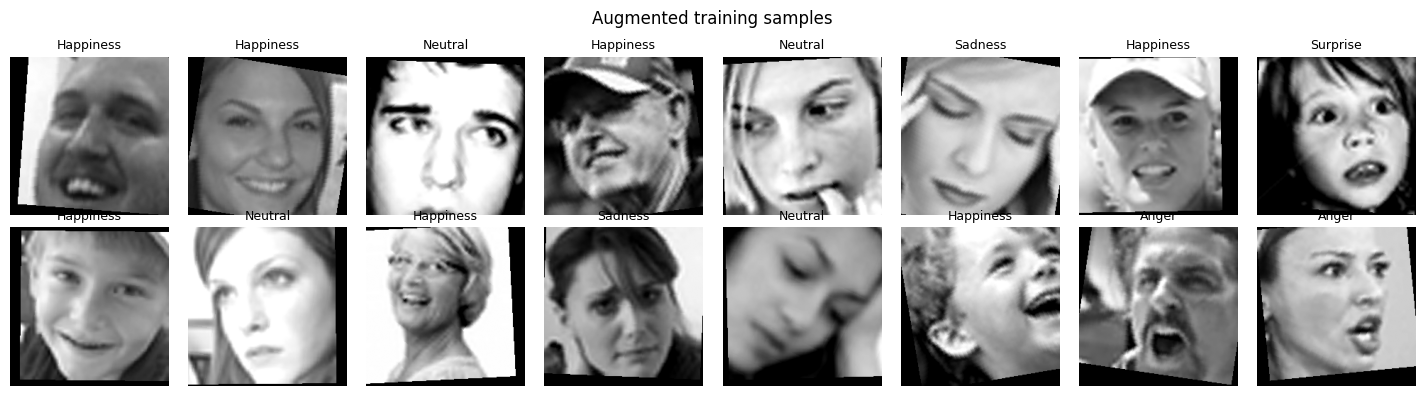

In [4]:
images, labels = next(iter(loaders["train"]))
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, image, label in zip(axes.ravel(), images, labels):
    # Undoing the normalization allows the true gray levels of the face to be displayed.
    ax.imshow((image[0] * 0.229 + 0.485).clamp(0, 1), cmap="gray")
    ax.set_title(CLASSES[label], fontsize=9)
    ax.axis("off")
plt.suptitle("Augmented training samples")
plt.tight_layout()
plt.show()

## 2. Model

ResNet-18 comprises 4 stages of residual modules (`layer1`-`layer4`). Skip-connections facilitate training of deep models. The original `fc` layer is substituted with `Dropout(0.3) and Linear(512, 6)`.

In [5]:
torch.manual_seed(SEED)
model = models.resnet18(weights="IMAGENET1K_V1")
# The 1000-class ImageNet output layer is replaced by the new 6-class classifier section.
model.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.fc.in_features, len(CLASSES)))
model = model.to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f}M")
print("new head:", getattr(model, HEAD))

parameters: 11.18M
new head: Sequential(
  (0): Dropout(p=0.3, inplace=False)
  (1): Linear(in_features=512, out_features=6, bias=True)
)


## 3. Stage 1: train only the new head

In [6]:
# Mixed precision approximately halves GPU training duration. However, it is disabled on the CPU.
use_amp = device.type == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=use_amp)


def run_epoch(model, loader, optimizer=None):
    # A single pass over a loader. If an optimizer is given, the model is trained. Otherwise, it is only evaluated.
    # Loss value, accuracy, macro F1 and predicted classes are returned.
    training = optimizer is not None
    model.train(training)
    total_loss, y_true, y_pred = 0.0, [], []
    with torch.set_grad_enabled(training):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            with torch.autocast(device.type, enabled=use_amp):
                logits = model(x)
                loss = criterion(logits, y)
            if training:
                optimizer.zero_grad()
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * len(y)
            y_true += y.tolist()
            y_pred += logits.argmax(1).tolist()
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    return total_loss / len(y_true), (y_true == y_pred).mean(), f1_score(y_true, y_pred, average="macro"), y_pred


def fit(model, optimizer, scheduler, epochs, patience, history=None):
    # Early stopping is applied according to the validation macro F1. Best model weights are reloaded at the end of
    # training. An existing history can be supplied to continue the curves of an earlier stage.
    history = {} if history is None else history
    best_f1, best_state, bad_epochs = -1.0, None, 0
    for epoch in range(1, epochs + 1):
        start = time.time()
        lr = optimizer.param_groups[0]["lr"]
        train_loss, train_acc, _, _ = run_epoch(model, loaders["train"], optimizer)
        val_loss, val_acc, val_f1, _ = run_epoch(model, loaders["valid"])
        if scheduler is not None:
            scheduler.step()
        values = {"train_loss": train_loss, "train_acc": train_acc, "val_loss": val_loss, "val_acc": val_acc,
                  "val_macro_f1": val_f1, "lr": lr}
        for key, value in values.items():
            history.setdefault(key, []).append(float(value))
        print(f"epoch {epoch:3d} | train loss {train_loss:.4f} acc {train_acc:.3f} | val loss {val_loss:.4f} "
              f"acc {val_acc:.3f} f1 {val_f1:.3f} | lr {lr:.1e} | {time.time() - start:.0f}s")
        if val_f1 > best_f1:
            best_f1, best_state, bad_epochs = val_f1, copy.deepcopy(model.state_dict()), 0
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                print(f"No improvement for {patience} epochs, stopping.")
                break
    model.load_state_dict(best_state)
    history["best_val_macro_f1"] = float(best_f1)
    return history


def set_trainable(prefixes):
    # All parameters are frozen except those with names beginning with one of the given prefixes. Passing None
    # unfreezes the whole network.
    for param_name, param in model.named_parameters():
        param.requires_grad = prefixes is None or param_name.startswith(tuple(prefixes))


def make_optimizer(backbone_lr, head_lr):
    # The new classifier section is given a higher learning rate than the pretrained sections, which only require
    # slight amendment. Frozen parameters are ignored.
    head = [p for n, p in model.named_parameters() if p.requires_grad and n.startswith(HEAD)]
    backbone = [p for n, p in model.named_parameters() if p.requires_grad and not n.startswith(HEAD)]
    return torch.optim.AdamW([{"params": head, "lr": head_lr}, {"params": backbone, "lr": backbone_lr}],
                             weight_decay=1e-4)


STAGE1_EPOCHS = 3
HEAD_LR = 1e-3

set_trainable([HEAD])
print(f"trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

start = time.time()
stage1_history = fit(model, make_optimizer(0.0, HEAD_LR), None, STAGE1_EPOCHS, patience=STAGE1_EPOCHS)
stage1_time = time.time() - start
stage1_state = copy.deepcopy(model.state_dict())

trainable parameters: 3,078


train:   0%|          | 0/388 [00:00<?, ?it/s]

epoch   1 | train loss 1.6246 acc 0.335 | val loss 1.3897 acc 0.440 f1 0.384 | lr 1.0e-03 | 156s  *


train:   0%|          | 0/388 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

epoch   2 | train loss 1.4826 acc 0.402 | val loss 1.3871 acc 0.393 f1 0.368 | lr 1.0e-03 | 164s


train:   0%|          | 0/388 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>
Exception ignored in: Traceback (most recent call last):
<function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
      File "/usr/local/lib/python3.13/dist-packages/tor

epoch   3 | train loss 1.4521 acc 0.413 | val loss 1.3426 acc 0.460 f1 0.391 | lr 1.0e-03 | 163s  *


## 4. Stage 2 tuning: how much to unfreeze, and how fast

All fine-tuning experiments begin at the same stage-1 model weights. The model is then fine-tuned for a small number of epochs. Different experiments are conducted to assess the impact of various (i) backbone learning rates and (ii) numbers of retrained model layers. The head is always trained at a 10× greater learning rate than the backbone. As before, the experiment attaining the greatest **validation macro F1** score is chosen.

In [7]:
# Prefixes for parameters that are trained during stage 2. (None indicates that all network parameters are
# trained.)
UNFREEZE = {"all": None, "last stage": ["layer4", "fc"]}

TUNING_EPOCHS = 4
grid = [
    {"unfreeze": "all", "backbone_lr": 1e-4},
    {"unfreeze": "all", "backbone_lr": 3e-5},
    {"unfreeze": "last stage", "backbone_lr": 1e-4},
]


def fine_tune(params, epochs, patience, history=None):
    # Each run restarts from the weights at the end of stage 1.
    model.load_state_dict(stage1_state)
    set_trainable(UNFREEZE[params["unfreeze"]])
    optimizer = make_optimizer(params["backbone_lr"], 10 * params["backbone_lr"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    return fit(model, optimizer, scheduler, epochs, patience, history)


tuning = []
for params in grid:
    print("\n", params)
    torch.manual_seed(SEED)
    history = fine_tune(params, TUNING_EPOCHS, patience=TUNING_EPOCHS)
    tuning.append({**params, "best val macro F1": round(history["best_val_macro_f1"], 4)})

tuning = pd.DataFrame(tuning).sort_values("best val macro F1", ascending=False)
tuning


 {'unfreeze': 'all', 'backbone_lr': 0.0001}


train:   0%|          | 0/388 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

epoch   1 | train loss 0.8908 acc 0.672 | val loss 0.6067 acc 0.772 f1 0.708 | lr 1.0e-03 | 176s  *


train:   0%|          | 0/388 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (28 outputs left out)

train:   0%|          | 0/388 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    <function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>if w.is_alive():

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    assert self._parent_pid == os.getpid(), 'can only test a child process'self._shutdown_workers()

AssertionError: can only test a child process  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

    if w.is_alive():
  File "/usr/lib/

epoch   4 | train loss 0.5787 acc 0.770 | val loss 0.5866 acc 0.792 f1 0.749 | lr 1.5e-04 | 160s  *


,unfreeze,backbone_lr,best val macro F1
0,all,0.00010,0.8152
1,all,0.00003,0.7589
2,last stage,0.00010,0.7487


## 5. Stage 2: final fine-tuning

The best setting is then fine-tuned for longer (with cosine learning rate decay). Early stopping is also implemented (patience = 5). The training curves continue from stage 1, with the commencement of fine-tuning indicated by the dashed line.

In [8]:
best = tuning.iloc[0]
BEST = {"unfreeze": best["unfreeze"], "backbone_lr": float(best["backbone_lr"])}
STAGE2_EPOCHS = 15
print("final settings:", BEST)

torch.manual_seed(SEED)
history = copy.deepcopy(stage1_history)
# The commencement of fine-tuning (indicated by a dashed line on the graphs).
history["stage2_start"] = len(history["train_loss"]) + 1
start = time.time()
history = fine_tune(BEST, STAGE2_EPOCHS, patience=5, history=history)
train_time = stage1_time + time.time() - start
print(f"total training time: {train_time / 60:.1f} min")

final settings: {'unfreeze': 'all', 'backbone_lr': 0.0001}


train:   0%|          | 0/388 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>Exception ignored in: 
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()<function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
if w.is_alive():  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    if w.is_alive():    
assert self._parent_pid == os.getpid(), 'can only test a child process'  File "/usr/lib/python3.13/multiprocessing/process.py", line 16

epoch   1 | train loss 0.8908 acc 0.672 | val loss 0.6067 acc 0.772 f1 0.708 | lr 1.0e-03 | 167s  *


train:   0%|          | 0/388 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

... (36 outputs left out)

epoch  14 | train loss 0.1190 acc 0.944 | val loss 0.5938 acc 0.867 f1 0.828 | lr 4.3e-05 | 71s  *


train:   0%|          | 0/388 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    Exception ignored in: assert self._parent_pid == os.getpid(), 'can only test a child process'<function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>

Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
AssertionError    : can only test a child processself._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

epoch  15 | train loss 0.1179 acc 0.945 | val loss 0.5946 acc 0.869 f1 0.829 | lr 1.1e-05 | 76s  *
total training time: 31.6 min


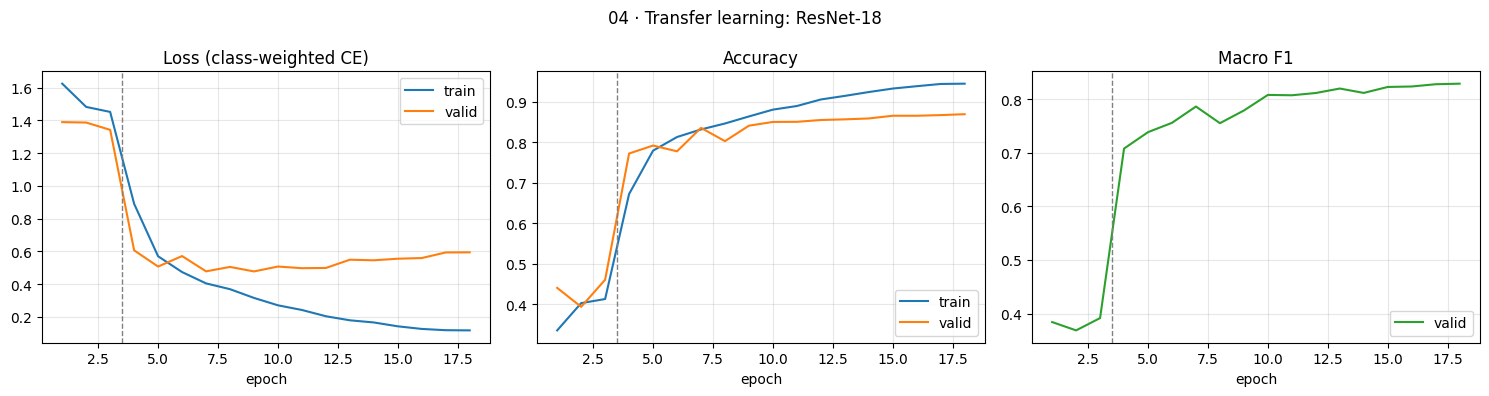

In [9]:
epochs = range(1, len(history["train_loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(epochs, history["train_loss"], label="train")
axes[0].plot(epochs, history["val_loss"], label="valid")
axes[0].set_title("Loss (class-weighted cross-entropy)")
axes[1].plot(epochs, history["train_acc"], label="train")
axes[1].plot(epochs, history["val_acc"], label="valid")
axes[1].set_title("Accuracy")
axes[2].plot(epochs, history["val_macro_f1"], color="tab:green", label="valid")
axes[2].set_title("Macro F1")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
    ax.axvline(history["stage2_start"] - 0.5, color="gray", linestyle="--", linewidth=1)
fig.suptitle("04 · Transfer learning: ResNet-18")
fig.tight_layout()
fig.savefig(FIG / "resnet18_curves.png", dpi=150)
plt.show()

## 6. Test results

In [10]:
start = time.time()
_, _, _, y_pred = run_epoch(model, loaders["test"])
ms_per_image = 1000 * (time.time() - start) / len(y_test)

test_metrics = compute_metrics(y_test, y_pred)
print(f"accuracy {test_metrics['accuracy']:.4f}, macro F1 {test_metrics['macro_f1']:.4f}")
print(pd.DataFrame(test_metrics["per_class"]).T.round(3))

# Same statistics but for test images not also present in the training data.
clean_metrics = compute_metrics(y_test[~in_train], y_pred[~in_train])
print(f"\nclean test subset ({(~in_train).sum()} images): accuracy {clean_metrics['accuracy']:.4f}, "
      f"macro F1 {clean_metrics['macro_f1']:.4f}")

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():Exception ignored in: 
<function _MultiProcessingDataLoaderIter.__del__ at 0x7f21a3784900>
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
Traceback (most recent call last):
      File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
assert self._parent_pid == os.getpid(), 'can only test a child process'
    AssertionError: can only test a child processself._shutdown_workers()

  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():Exception ignored 

accuracy  0.8753
macro F1  0.8312
class        prec recall     f1      n
Neutral     0.908  0.845  0.875   1081
Happiness   0.939  0.939  0.939    891
Surprise    0.858  0.935  0.895    400
Sadness     0.720  0.805  0.760    384
Anger       0.840  0.891  0.865    266
Fear        0.767  0.568  0.652     81

clean test subset (2874 images): accuracy 0.8723, macro F1 0.8254


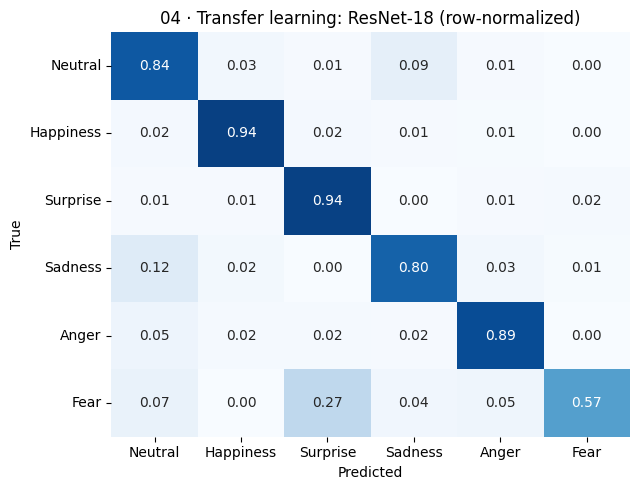

In [11]:
cm = np.array(test_metrics["confusion_matrix"])
fig, ax = plt.subplots(figsize=(6.5, 5))
# Each row is divided by its sum. Diagonal entries then indicate the recall for each class.
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set(xlabel="Predicted", ylabel="True", title="04 · Transfer learning: ResNet-18 (row-normalized)")
plt.tight_layout()
fig.savefig(FIG / "resnet18_confusion.png", dpi=150)
plt.show()

In [12]:
torch.save({"model_name": MODEL_NAME, "classes": CLASSES, "state_dict": model.state_dict(),
            "model_kwargs": {"dropout": 0.3}}, MODELS_DIR / f"{MODEL_NAME}.pt")

metrics = {
    "model": MODEL_NAME,
    "test": test_metrics,
    "test_clean": clean_metrics,
    "val_macro_f1": history["best_val_macro_f1"],
    "hyperparameters": {**BEST, "head_lr_stage1": HEAD_LR, "head_lr_stage2": 10 * BEST["backbone_lr"],
                        "batch_size": BATCH_SIZE, "optimizer": "AdamW", "weight_decay": 1e-4,
                        "scheduler": "CosineAnnealingLR", "stage1_epochs": STAGE1_EPOCHS,
                        "stage2_max_epochs": STAGE2_EPOCHS, "imagenet_weights": True},
    "tuning": tuning.to_dict("records"),
    "history": history,
    "parameters": sum(p.numel() for p in model.parameters()),
    "train_time_sec": round(train_time, 1),
    "inference_ms_per_image": round(ms_per_image, 3),
    "device": str(device),
}
(RESULTS_DIR / "metrics" / f"{MODEL_NAME}.json").write_text(json.dumps(metrics, indent=2))

saved /content/drive/My Drive/LSU - Masters/CSC 7333/Final Project/results/metrics/resnet18.json


## 7. Observations

_[To be completed following Colab execution.] What was achieved by stage-1 training? How much additional performance was gained via fine-tuning? Which method of retraining was most effective? How does 04 · Transfer learning: ResNet-18 fare in comparison to the CNN from scratch?_

> **After training on Colab:** download `MyDrive/ferplus/results/metrics/resnet18.json`, along with the figures from `MyDrive/ferplus/results/figures/` and `MyDrive/ferplus/models/resnet18.pt`, to the corresponding directories in the repo. Add the JSON, the graphs and the model weights (the `.pt` file) to git.